<a href="https://colab.research.google.com/github/godfreyM04/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercise 3B: Implementation of UCS**

The program below models the directed graph in the design.md implementing a step by step Uniform Cost search to find the optimal path.

**How it works:**

Main section models the highway network using an adjacency list dictionary.

The uniform_cost_search() function initialises the tracking mechanisms.It initialises the priority queue frontier which stores the active paths as a tuple of cumulative cost, the current node and the path taken. On the other hand the distance_table records the shortest known path from Nairobi to every node in the graph and is first initialised to infinity.

The while loop enforces iterations where the priority queue heapq.heappop() repeatedly pops the node with the smallest cumulative cost. Once a node is popped the program checks if it is already in the explored set. If unvisited, it is marked as explored and a goal test is performed to confirm whether Kisumu is the current node. If Kisumu is reached, the search stops and the optimal path is returned. Else, the loop iterates through the neighbouring nodes, calculates new path costs and updates the frontier when a shorter route to a neighbour is discovered.




In [6]:
import heapq

def uniform_cost_search(graph, start_node, goal_node):
    """
    Executes Uniform Cost Search (UCS / Dijkstra's Algorithm) to find the
    optimal path from start_node to goal_node across the highway network.
    """
    # Priority Queue (Frontier): stores tuples of (cumulative_cost, current_node, path_taken)
    frontier = []
    heapq.heappush(frontier, (0, start_node, [start_node]))

    # Track minimal cost to reach each node for optimal traversal
    distance_table = {node: float('inf') for node in graph}
    distance_table[start_node] = 0

    # Track parent node for path reconstruction trace
    previous_node = {node: None for node in graph}

    # Explored set tracking visited nodes
    explored = set()

    iteration = 0

    print(f"UNIFORM COST SEARCH (UCS) TRAVERSAL: {start_node} TO {goal_node}")


    while frontier:
        iteration += 1
        # Pop node with the smallest cumulative cost g(n) from the priority queue
        cost, current, path = heapq.heappop(frontier)

        # Skip processing if already expanded via a shorter/equal cost route
        if current in explored:
            continue

        # Mark node as visited/explored
        explored.add(current)

        print(f"\n--- ITERATION {iteration} ---")
        print(f"Current Node Expanded : {current}")
        print(f"Cumulative Cost g(n)  : {cost} km")
        print(f"Current Path          : {' -> '.join(path)}")
        print(f"Explored Set          : {sorted(list(explored))}")

        # Goal Test: Checked when node is popped from priority queue
        if current == goal_node:
            print("\nGOAL STATE REACHED!")
            return path, cost

        # Expand unvisited neighbors of current node
        for neighbor, step_cost in graph.get(current, []):
            new_cost = cost + step_cost

            # If a shorter path to neighbor is found, update tables and frontier
            if new_cost < distance_table[neighbor]:
                distance_table[neighbor] = new_cost
                previous_node[neighbor] = current
                heapq.heappush(frontier, (new_cost, neighbor, path + [neighbor]))
                print(f"  -> Frontier Update: Discovered {neighbor} via {current} | Cost: {new_cost} km")

    return None, float('inf')


if __name__ == "__main__":
    # Directed Graph Representation (Adjacency List)
    # Edge weights represent highway distances in kilometers (km)
    kenya_highway_network = {
        'Nairobi': [('Naivasha', 88)],
        'Naivasha': [('Nakuru', 70)],
        'Nakuru': [('Kericho', 107), ('Eldoret', 128)],
        'Kericho': [('Kisumu', 83)],
        'Eldoret': [('Kisumu', 117)],
        'Kisumu': []
    }

    start = 'Nairobi'
    goal = 'Kisumu'

    # Execute Search
    optimal_path, total_cost = uniform_cost_search(kenya_highway_network, start, goal)

    # Output Final Results
    print(f"\nOPTIMAL PATH  : {' -> '.join(optimal_path)}")
    print(f"TOTAL PATH COST: {total_cost} km\n")

UNIFORM COST SEARCH (UCS) TRAVERSAL: Nairobi TO Kisumu

--- ITERATION 1 ---
Current Node Expanded : Nairobi
Cumulative Cost g(n)  : 0 km
Current Path          : Nairobi
Explored Set          : ['Nairobi']
  -> Frontier Update: Discovered Naivasha via Nairobi | Cost: 88 km

--- ITERATION 2 ---
Current Node Expanded : Naivasha
Cumulative Cost g(n)  : 88 km
Current Path          : Nairobi -> Naivasha
Explored Set          : ['Nairobi', 'Naivasha']
  -> Frontier Update: Discovered Nakuru via Naivasha | Cost: 158 km

--- ITERATION 3 ---
Current Node Expanded : Nakuru
Cumulative Cost g(n)  : 158 km
Current Path          : Nairobi -> Naivasha -> Nakuru
Explored Set          : ['Nairobi', 'Naivasha', 'Nakuru']
  -> Frontier Update: Discovered Kericho via Nakuru | Cost: 265 km
  -> Frontier Update: Discovered Eldoret via Nakuru | Cost: 286 km

--- ITERATION 4 ---
Current Node Expanded : Kericho
Cumulative Cost g(n)  : 265 km
Current Path          : Nairobi -> Naivasha -> Nakuru -> Kericho
Explo

**To visualize the optimal path in the directed graph:**

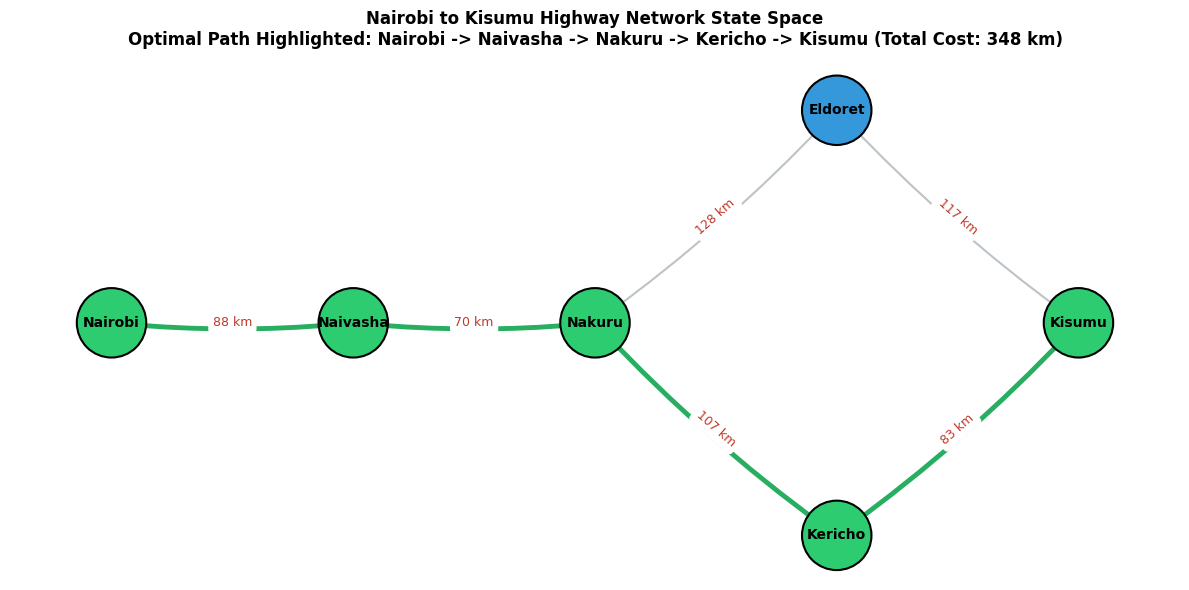

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

def visualize_highway_network():
    # 1. Define the directed graph representation from Exercise 3B
    kenya_highway_network = {
        'Nairobi': [('Naivasha', 88)],
        'Naivasha': [('Nakuru', 70)],
        'Nakuru': [('Kericho', 107), ('Eldoret', 128)],
        'Kericho': [('Kisumu', 83)],
        'Eldoret': [('Kisumu', 117)],
        'Kisumu': []
    }

    # 2. Define the optimal path determined by Uniform Cost Search (UCS)
    optimal_path = ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu']
    optimal_edges = list(zip(optimal_path[:-1], optimal_path[1:]))

    # 3. Create NetworkX Directed Graph (DiGraph)
    G = nx.DiGraph()

    # Populate graph with edges and distance weights
    for u, neighbors in kenya_highway_network.items():
        for v, weight in neighbors:
            G.add_edge(u, v, weight=weight)

    # 4. Set explicit node positions for clean geographical flow (Westward traversal)
    pos = {
        'Nairobi': (0, 0),
        'Naivasha': (2, 0),
        'Nakuru': (4, 0),
        'Kericho': (6, -1),
        'Eldoret': (6, 1),
        'Kisumu': (8, 0)
    }

    # 5. Define node and edge color maps
    # Optimal nodes get highlighted in distinct color (light green), standard nodes in light blue
    node_colors = [
        '#2ecc71' if node in optimal_path else '#3498db'
        for node in G.nodes()
    ]

    # Optimal path edges get highlighted in dark green, standard edges in grey
    edge_colors = [
        '#27ae60' if edge in optimal_edges else '#bdc3c7'
        for edge in G.edges()
    ]

    # Edge width highlighting
    edge_widths = [
        3.5 if edge in optimal_edges else 1.5
        for edge in G.edges()
    ]

    # 6. Render Visualization
    plt.figure(figsize=(12, 6))
    plt.title(
        "Nairobi to Kisumu Highway Network State Space\n"
        "Optimal Path Highlighted: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu (Total Cost: 348 km)",
        fontsize=12, fontweight='bold', pad=15
    )

    # Draw nodes and labels
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2500, edgecolors='black', linewidths=1.5)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', font_family='sans-serif')

    # Draw directed edges (arrows)
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        width=edge_widths,
        arrowstyle='->',
        arrowsize=20,
        connectionstyle="arc3,rad=0.05"
    )

    # Draw edge distance labels (km)
    edge_labels = nx.get_edge_attributes(G, 'weight')
    formatted_edge_labels = {k: f"{v} km" for k, v in edge_labels.items()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=formatted_edge_labels, font_size=9, font_color='#c0392b')

    # Configure plot margins and display
    plt.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualize_highway_network()

**Here's a cool group photo we took during one of our session**

![GroupImage](https://drive.google.com/uc?id=1Dyjc_LCbDfmsORTBa3-kPWCqmkP3JeuI)